# Simple transformer with backprop

We will train a _tiny_ Transformer language model to predict the next character in a sequence.

The goal is to demonstrate the basic training process used by language models, without introducing additional techniques such as label smoothing.

The model will:
1. Convert characters into numerical tokens.
2. Process the tokens using a small Transformer with causal attention, so each position can only attend to earlier positions and itself.
3. Predict the next character at each position.
4. Calculate the prediction error using cross-entropy loss.
5. Update its parameters using backpropagation and gradient descent.
6. Generate a short sample of text after training.

**Key idea:** A language model learns by repeatedly predicting the next token, measuring its error, and adjusting its parameters to improve future predictions.

This is a deliberately tiny, character-level demonstration.

- Real large language models use much larger datasets, token vocabularies, Transformer architectures, and substantially more computation.

- This demonstrates the mechanics of training a GPT-style Transformer, not the scale or capabilities of a real LLM. It uses character-level tokens and a tiny repeated text corpus; a production language model uses a much larger corpus, a subword tokenizer, and vastly more parameters and training steps.


In [2]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. Create a tiny training corpus and character vocabulary.
text = (
    "a language model learns patterns in text. "
    "a transformer uses attention to process tokens. "
) * 100

chars = sorted(set(text))
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = torch.tensor([stoi[ch] for ch in text], dtype=torch.long, device=device)
vocab_size = len(chars)


# 2. Define a small Transformer language model.
class TinyTransformerLM(nn.Module):
    def __init__(self, vocab_size, d_model=32, n_heads=4,
                 n_layers=2, max_len=64):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_len, d_model)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=64,
            dropout=0.0,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.output_layer = nn.Linear(d_model, vocab_size)
        self.max_len = max_len

    def forward(self, x):
        batch_size, seq_len = x.shape

        positions = torch.arange(seq_len, device=x.device).unsqueeze(0)
        h = self.token_embedding(x) + self.position_embedding(positions)

        # Causal mask: prevent looking at future characters.
        causal_mask = torch.triu(
            torch.ones(seq_len, seq_len, device=x.device,
                       dtype=torch.bool),
            diagonal=1
        )

        h = self.transformer(h, mask=causal_mask)
        return self.output_layer(h)


model = TinyTransformerLM(vocab_size).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


# 3. Training loop: predict the next character.
seq_len = 32
batch_size = 32
steps = 300

for step in range(steps):
    # Sample random sequences from the training text.
    starts = torch.randint(
        0, len(data) - seq_len - 1, (batch_size,), device=device
    )

    x = torch.stack([data[s:s + seq_len] for s in starts])
    y = torch.stack([data[s + 1:s + seq_len + 1] for s in starts])

    # Forward pass: predict the next character at every position.
    logits = model(x)

    # Compare predictions with the correct next characters.
    loss = F.cross_entropy(
        logits.reshape(-1, vocab_size),
        y.reshape(-1)
    )

    # Backpropagation and parameter update.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (step + 1) % 50 == 0:
        print(f"Step {step + 1:3d}/{steps} | Loss: {loss.item():.3f}")


# 4. Generate a short sample from the trained model.
model.eval()
context = torch.tensor([[stoi["a"]]], device=device)

with torch.no_grad():
    for _ in range(100):
        context_window = context[:, -model.max_len:]
        next_logits = model(context_window)[:, -1, :]
        probabilities = F.softmax(next_logits, dim=-1)
        next_token = torch.multinomial(probabilities, num_samples=1)
        context = torch.cat([context, next_token], dim=1)

print("\nGenerated text:")
print("".join(itos[i] for i in context[0].tolist()))

Step  50/300 | Loss: 2.081
Step 100/300 | Loss: 1.520
Step 150/300 | Loss: 1.006
Step 200/300 | Loss: 0.604
Step 250/300 | Loss: 0.342
Step 300/300 | Loss: 0.216

Generated text:
age moke ces. arnses atttr toker prodesfexuses.s arnuoder us er ansns ans acesngerns ansfor ater prns


## Understanding the Training Loop

These five lines are the heart of the practical:

```python
logits = model(x)

loss = F.cross_entropy(
    logits.reshape(-1, vocab_size),
    y.reshape(-1)
)

optimizer.zero_grad()
loss.backward()
optimizer.step()
```

### What does each line do?

| Code | Meaning |
|---|---|
| `model(x)` | The Transformer predicts the next character at each position. |
| `F.cross_entropy(...)` | Measures how far the predictions are from the correct next characters. |
| `optimizer.zero_grad()` | Clears gradients left over from the previous training step. |
| `loss.backward()` | Computes gradients showing how model parameters contributed to the error. |
| `optimizer.step()` | Updates the parameters to try to reduce future prediction errors. |

### An important teaching point

`x` and `y` are the same text shifted by one character. For example, if `x` contains `lang`, the corresponding targets are `angu`.

The model learns next-token prediction by repeatedly practising this task. It makes predictions, measures its errors, calculates gradients through backpropagation, and updates its parameters to improve future predictions.


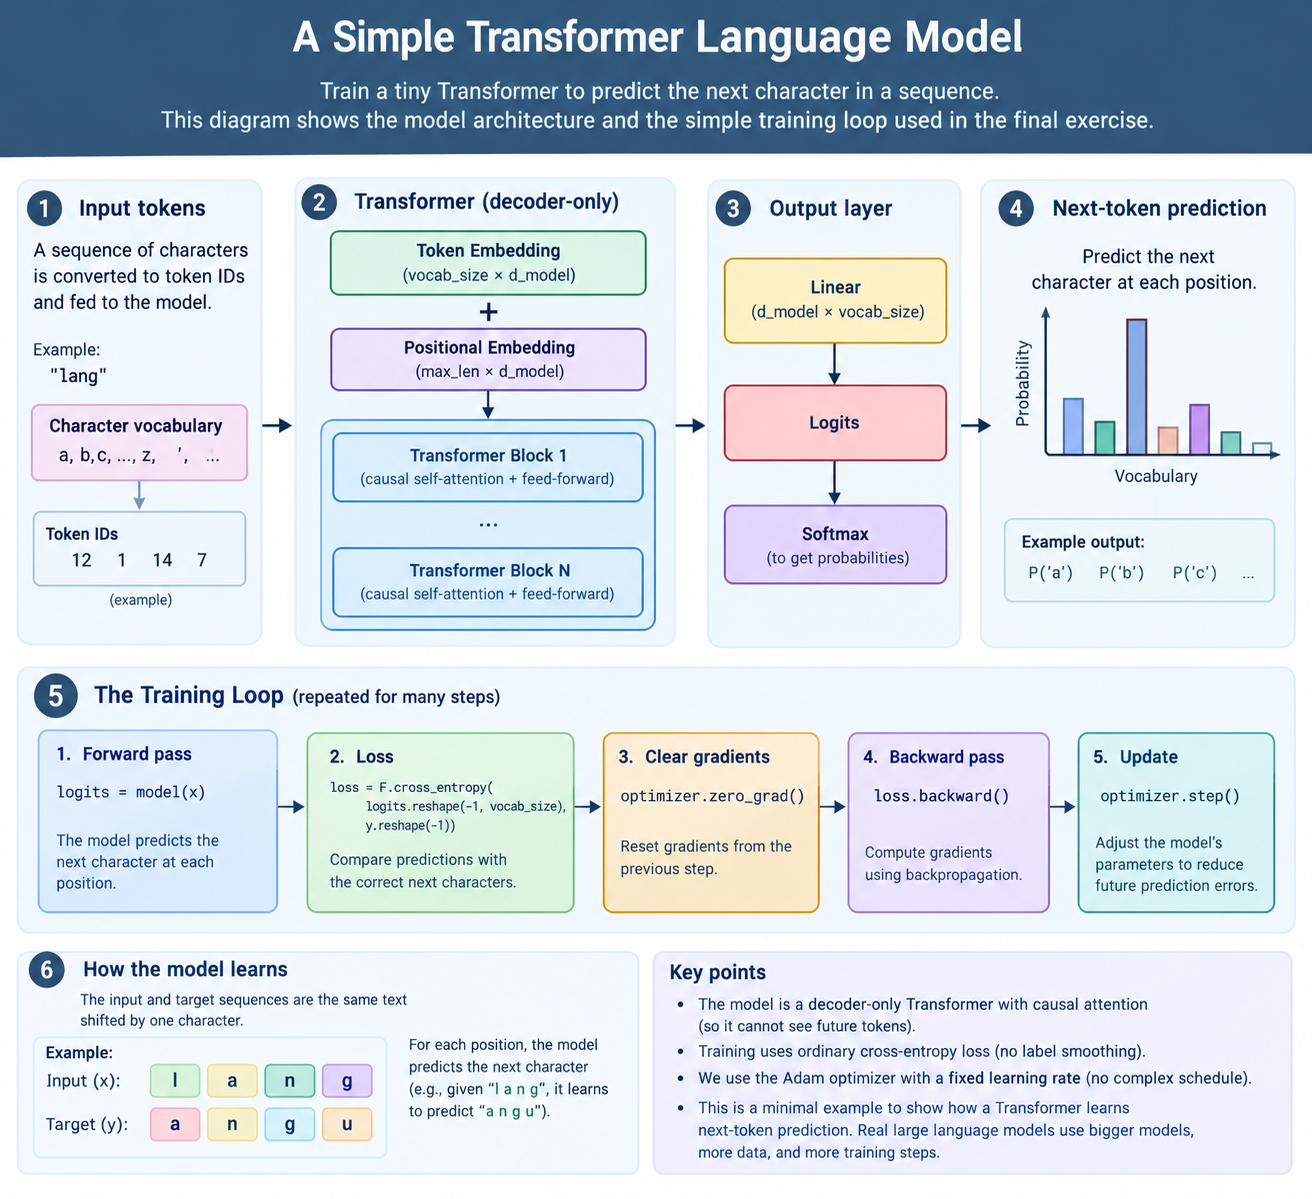

# Acknowledgements and declaration on generative AI use

Parts of the text and images are copied from that resource or generated using AI. I make no claims to originality. All material belongs to the respective creators. This is made for educational purposes only.

# References

- [Annotated Transformer](https://nlp.seas.harvard.edu/2018/04/03/attention.html)
- [Illustrated Transformer by Jay Alammar](https://jalammar.github.io/illustrated-transformer/)
- [🎥Transformers video by Grant Sanderson _3blue1brown_](https://www.youtube.com/watch?v=KJtZARuO3JY&t=177s)
- [Transformer tutorial by `Tensorflow` and _Francois Chollet_](https://www.tensorflow.org/text/tutorials/transformer)